# Tarea 1 - Unidad 2: Aprendizaje Profundo
**Alumno:** Victoria Galvan Delgadillo

In [2]:
import keras
from keras import layers
import keras.ops as ops
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar y normalizar los datos
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Normalizar los píxeles para que estén entre 0 y 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Aplanar las imágenes de 28x28 en vectores de 784 dimensiones
x_train = x_train.reshape((len(x_train), np.prod(x_train.shape[1:])))
x_test = x_test.reshape((len(x_test), np.prod(x_test.shape[1:])))

# Nombres de las 10 clases de Fashion-MNIST
class_names = ['Playera', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo',
               'Sandalia', 'Camisa', 'Tenis', 'Bolsa', 'Bota']

print(f"Forma de los datos de entrenamiento: {x_train.shape}")

I0000 00:00:1792149099.970793   26274 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792149100.007436   26274 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792149100.941479   26274 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Forma de los datos de entrenamiento: (60000, 784)


## 1. Hiperparámetros
A continuación se establecen los parámetros clave para configurar la arquitectura y el entrenamiento de la red:
* `latent_dim`: Dimensión del espacio latente (tamaño del cuello de botella).
* `hidden_layers`: Arquitectura de las capas densas ocultas. Modificar esta lista altera la profundidad del modelo.
* `betas`: Lista de coeficientes $\beta$ a evaluar. Se entrenará un modelo independiente para cada valor, permitiendo analizar el impacto de la regularización.

In [3]:
original_dim = 784            # 28x28 píxeles
latent_dim = 16               # prueba con 2, 8, 16, 32
hidden_layers = [256, 128]    # prueba con [128], [256, 128], [512, 256, 128]

betas = [0.5, 1.0, 4.0]
epochs = 15
batch_size = 256

## 2. Capa de Muestreo 
Para permitir la propagación hacia atrás, implementamos el truco de reparametrización. Esta capa personalizada genera el vector latente $z$ a partir de la media (`z_mean`) y el logaritmo de la varianza (`z_log_var`) producidos por el codificador, introduciendo ruido gaussiano $\epsilon$.

In [4]:
class Sampling(layers.Layer):
    """Usa (z_mean, z_log_var) para muestrear z, el vector que codifica una prenda."""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = ops.shape(z_mean)[0]
        dim = ops.shape(z_mean)[1]
        epsilon = keras.random.normal(shape=(batch, dim))
        return z_mean + ops.exp(0.5 * z_log_var) * epsilon

## 3. Construcción del Codificador y Decodificador
Se definen funciones modulares para instanciar componentes nuevos para cada configuración de $\beta$.
* **Codificador (Encoder):** Procesa los datos de entrada a través de capas densas y divide la salida en dos vectores (`z_mean` y `z_log_var`), los cuales alimentan la capa de muestreo probabilístico.
* **Decodificador (Decoder):** Toma el vector latente $z$ y proyecta la información en orden inverso a través de las capas ocultas. La capa final utiliza una activación sigmoide para acotar los píxeles reconstruidos entre 0 y 1.

In [5]:
def build_encoder():
    encoder_inputs = keras.Input(shape=(original_dim,))
    x = encoder_inputs
    for units in hidden_layers:
        x = layers.Dense(units, activation="relu")(x)

    # El VAE se divide en media y log-varianza
    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    z = Sampling()([z_mean, z_log_var])

    return keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")


def build_decoder():
    decoder_inputs = keras.Input(shape=(latent_dim,))
    x = decoder_inputs
    for units in reversed(hidden_layers):
        x = layers.Dense(units, activation="relu")(x)
    decoder_outputs = layers.Dense(original_dim, activation="sigmoid")(x)

    return keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# Vistazo a la arquitectura
build_encoder().summary()
build_decoder().summary()

E0000 00:00:1792149102.099407   26274 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    200,960 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 16)        │      2,064 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 16)        │      2,064 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 16)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 237,984 (929.62 KB)

 Trainable params: 237,984 (929.62 KB)

...

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 236,688 (924.56 KB)

 Trainable params: 236,688 (924.56 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Definición del Modelo Beta-VAE y Función de Pérdida
La arquitectura se entrena optimizando una función de pérdida compuesta. A diferencia del VAE estándar, el término de divergencia Kullback-Leibler (KL) se pondera por el hiperparámetro $\beta$:

Se crea una clase que hereda de `keras.Model` y se sobrescribe el método `compute_loss`, permitiendo calcular la pérdida directamente con los tensores internos del codificador.

In [6]:
class BetaVAE(keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs):
        # Pasada hacia adelante normal
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)

    def compute_loss(self, x=None, y=None, y_pred=None, sample_weight=None):
        # Pasada por las capas internas
        z_mean, z_log_var, z = self.encoder(x)
        reconstruction = self.decoder(z)

        # Pérdida de reconstrucción (MSE escalado por el tamaño de la imagen)
        reconstruction_loss = ops.mean(
            keras.losses.mean_squared_error(x, reconstruction)
        ) * 784.0

        # Pérdida de divergencia KL
        kl_loss = -0.5 * (1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var))
        kl_loss = ops.mean(ops.sum(kl_loss, axis=1))

        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        # Pérdida total que se usa para entrenar: recon + beta * KL
        return reconstruction_loss + self.beta * kl_loss

## 5. Entrenamiento de los Modelos Beta-VAE
Se iterará sobre la lista predefinida de valores $\beta$ (0.5, 1.0 y 4.0). Para cada valor, se compilará y entrenará un modelo independiente durante 15 épocas. Los objetos resultantes y sus historiales de entrenamiento se almacenarán en diccionarios para su posterior análisis.

In [7]:
vaes = {}
histories = {}

for beta in betas:
    print(f"\n===== Entrenando Beta-VAE con beta = {beta} =====")
    keras.utils.set_random_seed(42)
    vae = BetaVAE(build_encoder(), build_decoder(), beta=beta)
    vae.compile(optimizer="adam")

    # Se pasa x_train como entrada y como objetivo
    histories[beta] = vae.fit(x_train, x_train, epochs=epochs, batch_size=batch_size, verbose=2)
    vaes[beta] = vae


===== Entrenando Beta-VAE con beta = 0.5 =====
Epoch 1/15
235/235 - 3s - 12ms/step - kl_loss: 8.6982 - reconstruction_loss: 38.4050
Epoch 2/15
235/235 - 2s - 8ms/step - kl_loss: 10.4730 - reconstruction_loss: 21.3273
Epoch 3/15
235/235 - 2s - 8ms/step - kl_loss: 10.5581 - reconstruction_loss: 18.8414
Epoch 4/15
235/235 - 2s - 8ms/step - kl_loss: 10.7639 - reconstruction_loss: 17.4539
Epoch 5/15
235/235 - 2s - 8ms/step - kl_loss: 10.8830 - reconstruction_loss: 16.6649
Epoch 6/15
235/235 - 2s - 8ms/step - kl_loss: 10.9423 - reconstruction_loss: 16.1174
Epoch 7/15
235/235 - 2s - 8ms/step - kl_loss: 11.0255 - reconstruction_loss: 15.6873
Epoch 8/15
235/235 - 2s - 8ms/step - kl_loss: 11.0883 - reconstruction_loss: 15.3781
Epoch 9/15
235/235 - 2s - 8ms/step - kl_loss: 11.1395 - reconstruction_loss: 15.1093
Epoch 10/15
235/235 - 2s - 8ms/step - kl_loss: 11.1815 - reconstruction_loss: 14.8447
Epoch 11/15
235/235 - 2s - 8ms/step - kl_loss: 11.2330 - reconstruction_loss: 14.6518
Epoch 12/15
235

## 6. Análisis de Curvas de Pérdida
En esta sección se visualizan tres métricas clave por época para cada modelo entrenado: la pérdida de reconstrucción, la divergencia KL y la pérdida total. Estas gráficas permiten observar el comportamiento y la convergencia del modelo bajo distintas penalizaciones.

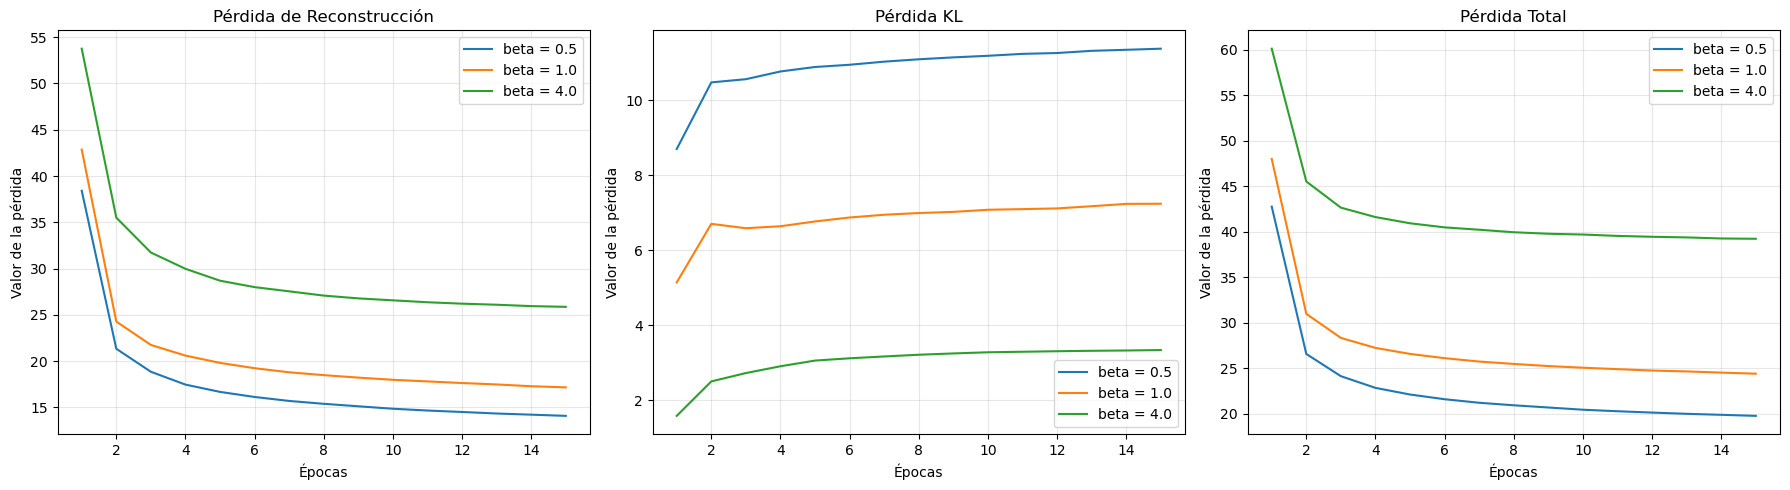

beta=0.5: recon=14.08 | KL=11.37
beta=1.0: recon=17.16 | KL=7.24
beta=4.0: recon=25.86 | KL=3.34


In [8]:
plt.figure(figsize=(18, 5))

for beta in betas:
    # Extraer los valores del historial
    reconstruction_loss = histories[beta].history["reconstruction_loss"]
    kl_loss = histories[beta].history["kl_loss"]

    total_loss = [r + beta * k for r, k in zip(reconstruction_loss, kl_loss)]
    ep = range(1, len(total_loss) + 1)

    plt.subplot(1, 3, 1)
    plt.plot(ep, reconstruction_loss, label=f"beta = {beta}")
    plt.subplot(1, 3, 2)
    plt.plot(ep, kl_loss, label=f"beta = {beta}")
    plt.subplot(1, 3, 3)
    plt.plot(ep, total_loss, label=f"beta = {beta}")

titles = ["Pérdida de Reconstrucción", "Pérdida KL", "Pérdida Total"]
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.title(titles[i])
    plt.xlabel("Épocas")
    plt.ylabel("Valor de la pérdida")
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Valores finales
for beta in betas:
    h = histories[beta].history
    print(f"beta={beta}: recon={h['reconstruction_loss'][-1]:.2f} | KL={h['kl_loss'][-1]:.2f}")

## Análisis: 
Un valor de $\beta$ elevado fuerza al espacio latente a asemejarse fuertemente a una distribución normal estándar, lo que minimiza la divergencia KL, pero penaliza la veracidad de las imágenes reconstruidas (las imágenes tienden a ser más borrosas y la pérdida de reconstrucción sube). Por el contrario, un $\beta$ bajo relaja la restricción del espacio latente, sacrificando regularidad para priorizar la nitidez y precisión en la reconstrucción de los datos originales.

## 7. Visualización de Reconstrucciones
Comparativa visual del desempeño de los modelos. La primera fila muestra imágenes originales del conjunto de prueba. Las filas subsecuentes presentan la reconstrucción generada por cada variante del modelo Beta-VAE a partir de la media de su espacio latente ($z_{mean}$).

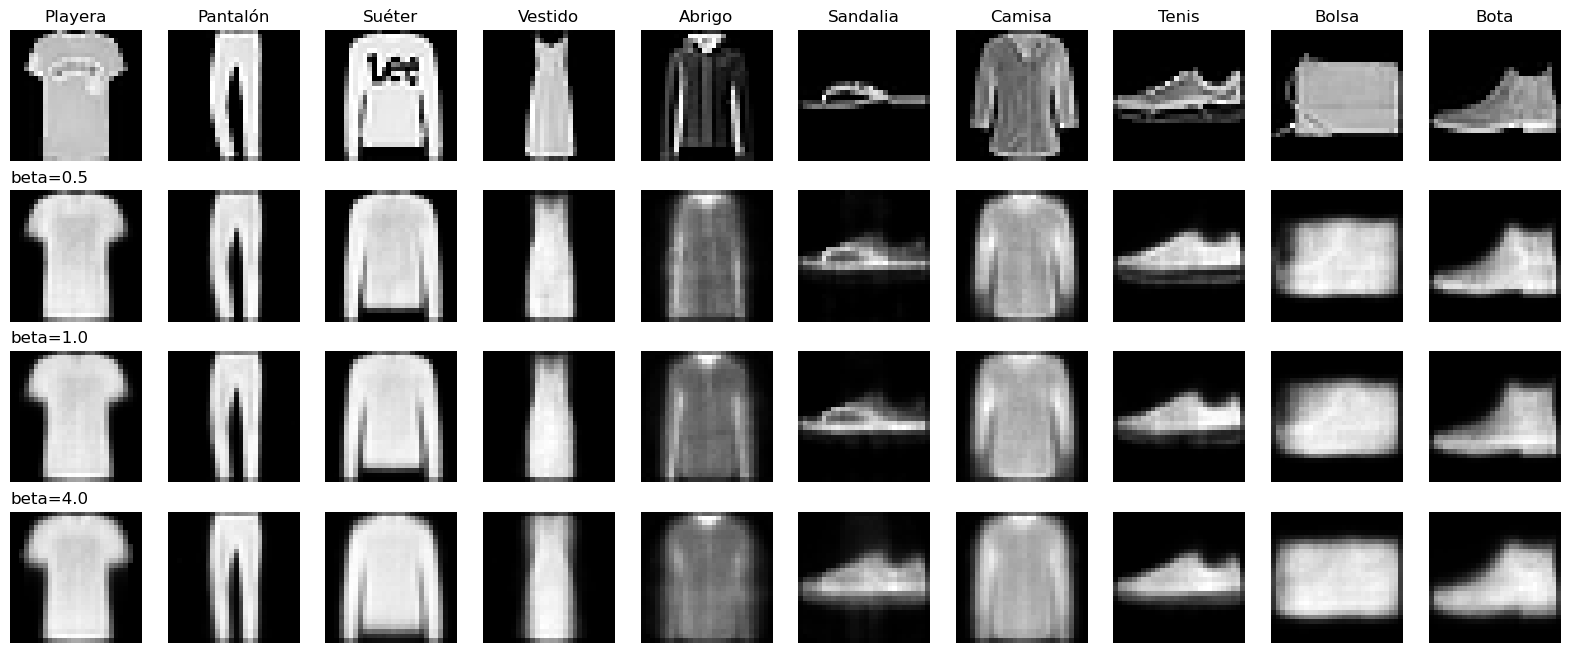

In [9]:
n = 10
# Una imagen de cada clase
examples = np.array([np.where(y_test == c)[0][0] for c in range(10)])
originals = x_test[examples]

plt.figure(figsize=(20, 2 * (len(betas) + 1)))
for i in range(n):
    plt.subplot(len(betas) + 1, n, i + 1)
    plt.imshow(originals[i].reshape(28, 28), cmap="gray")
    plt.title(class_names[i])
    plt.axis("off")

for r, beta in enumerate(betas):
    z_mean, _, _ = vaes[beta].encoder.predict(originals, verbose=0)
    recon = vaes[beta].decoder.predict(z_mean, verbose=0)
    for i in range(n):
        plt.subplot(len(betas) + 1, n, (r + 1) * n + i + 1)
        plt.imshow(recon[i].reshape(28, 28), cmap="gray")
        if i == 0:
            plt.title(f"beta={beta}", loc="left")
        plt.axis("off")
plt.show()

## 8. Generación de Nuevas Imágenes 
A diferencia de los Autoencoders tradicionales, los $\beta$-VAE son modelos probabilísticos generativos. En esta sección, generamos imágenes sintéticas muestreando puntos aleatorios desde una distribución normal estándar en el espacio latente. Estos vectores de ruido se introducen directamente en el Decodificador para observar la coherencia y diversidad de los dígitos artificiales creados.

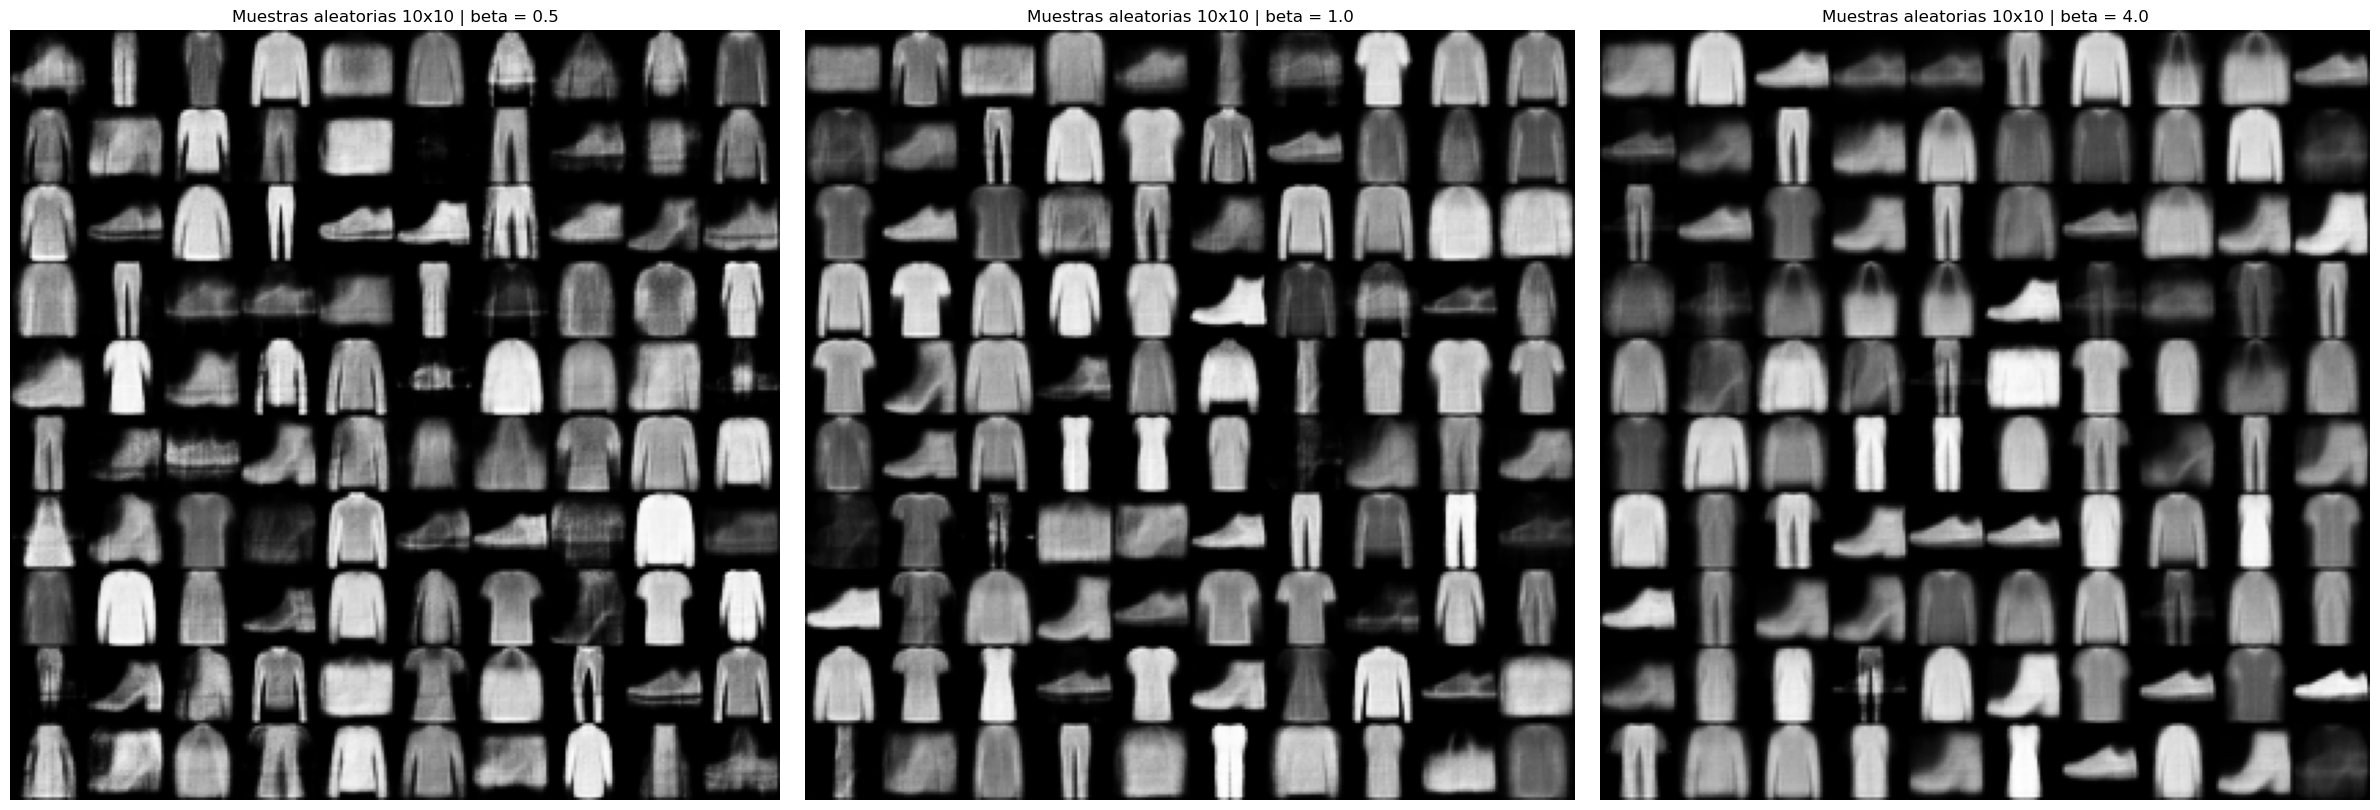

In [10]:
# 100 vectores latentes aleatorios (los mismos para todos los modelos)
random_latent_vectors = np.random.default_rng(7).standard_normal((100, latent_dim)).astype("float32")

plt.figure(figsize=(8 * len(betas), 8))
for k, beta in enumerate(betas):
    generated_images = vaes[beta].decoder.predict(random_latent_vectors, verbose=0)

    # Acomodar las 100 imágenes en una cuadrícula de 10x10
    grid = generated_images.reshape(10, 10, 28, 28).transpose(0, 2, 1, 3).reshape(280, 280)

    plt.subplot(1, len(betas), k + 1)
    plt.imshow(grid, cmap="gray")
    plt.title(f"Muestras aleatorias 10x10 | beta = {beta}")
    plt.axis("off")
plt.tight_layout()
plt.show()


## 9. Interpolación en el Espacio Latente 

Para un par de categorías relacionadas (A y B), la función de abajo hace lo siguiente:

1. **Localizar y extraer:** busca un ejemplo de prueba de cada clase.
2. **Codificar:** convierte ambas imágenes a sus coordenadas latentes medias ($z_{mean}$) para evitar el ruido del muestreo.
3. **Interpolar:** calcula $N = 10$ pasos con una combinación convexa.
4. **Decodificar y graficar:** decodifica cada paso para ver si los híbridos parecen prendas plausibles.


In [11]:
num_steps = 10
alphas = np.linspace(0, 1, num_steps)

def plot_transition(class_a, class_b, k=0):
    # Localizar una imagen de cada clase
    idx_a = np.where(y_test == class_a)[0][k]
    idx_b = np.where(y_test == class_b)[0][k]
    img_a = x_test[idx_a : idx_a + 1]
    img_b = x_test[idx_b : idx_b + 1]

    plt.figure(figsize=(20, 2.5 * len(betas)))
    for r, beta in enumerate(betas):
        # Codificar para obtener los centros latentes 
        z_mean_a, _, _ = vaes[beta].encoder.predict(img_a, verbose=0)
        z_mean_b, _, _ = vaes[beta].encoder.predict(img_b, verbose=0)

        interpolated_z = []
        for alpha in alphas:
            z_step = (1 - alpha) * z_mean_a + alpha * z_mean_b
            interpolated_z.append(z_step)
        interpolated_z = np.vstack(interpolated_z)

        # Decodificar el camino interpolado
        blended_images = vaes[beta].decoder.predict(interpolated_z, verbose=0)

        # Graficar la transición
        for i in range(num_steps):
            plt.subplot(len(betas), num_steps, r * num_steps + i + 1)
            plt.imshow(blended_images[i].reshape(28, 28), cmap="gray")

            # Etiquetar los extremos y los valores intermedios de alpha
            if i == 0:
                plt.title(f"{class_names[class_a]}\nbeta={beta}\n$\\alpha = 0.0$")
            elif i == num_steps - 1:
                plt.title(f"{class_names[class_b]}\n\n$\\alpha = 1.0$")
            else:
                plt.title(f"\n\n$\\alpha = {alphas[i]:.2f}$")
            plt.axis("off")

    plt.tight_layout()
    plt.show()

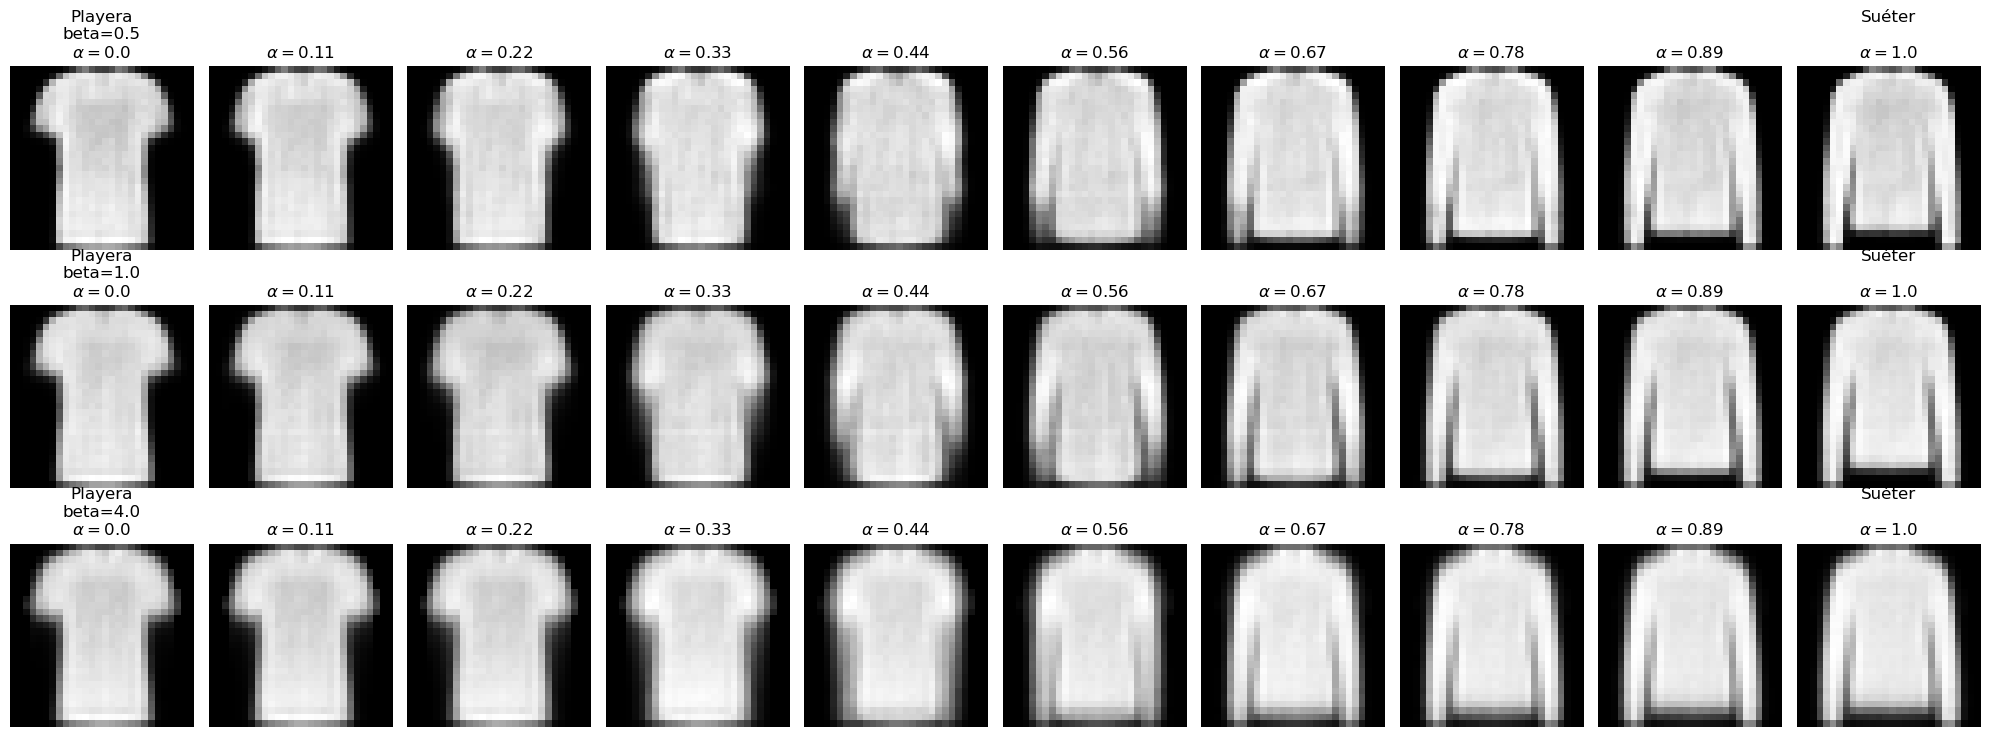

In [12]:
# Playera -> Suéter
plot_transition(0, 2)

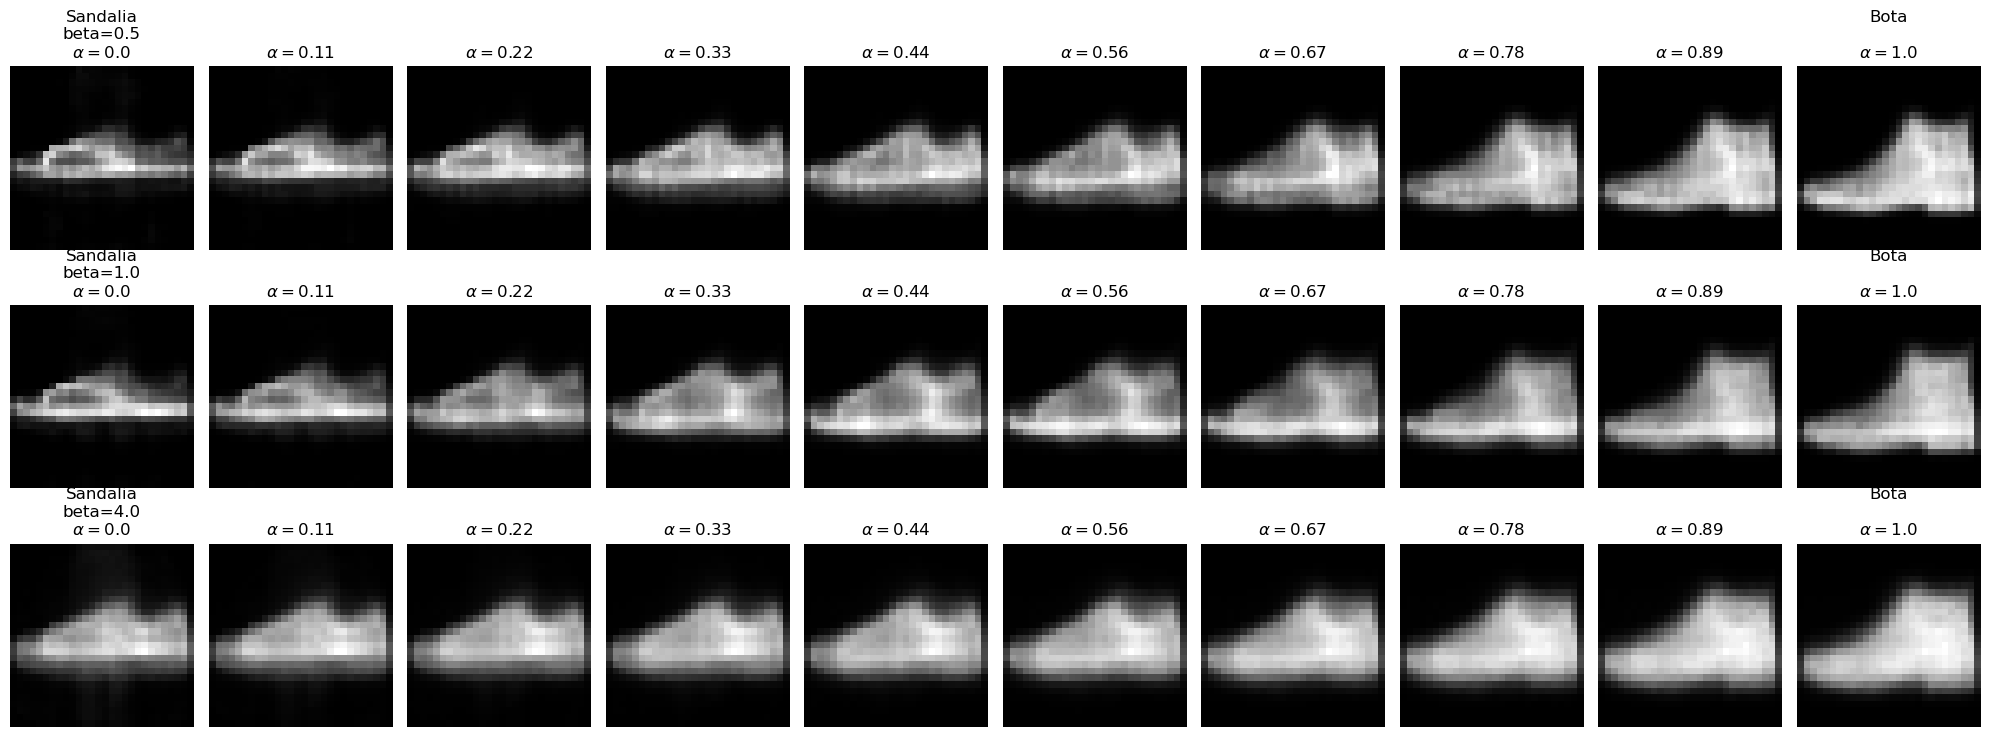

In [13]:
# Sandalia -> Bota
plot_transition(5, 9)

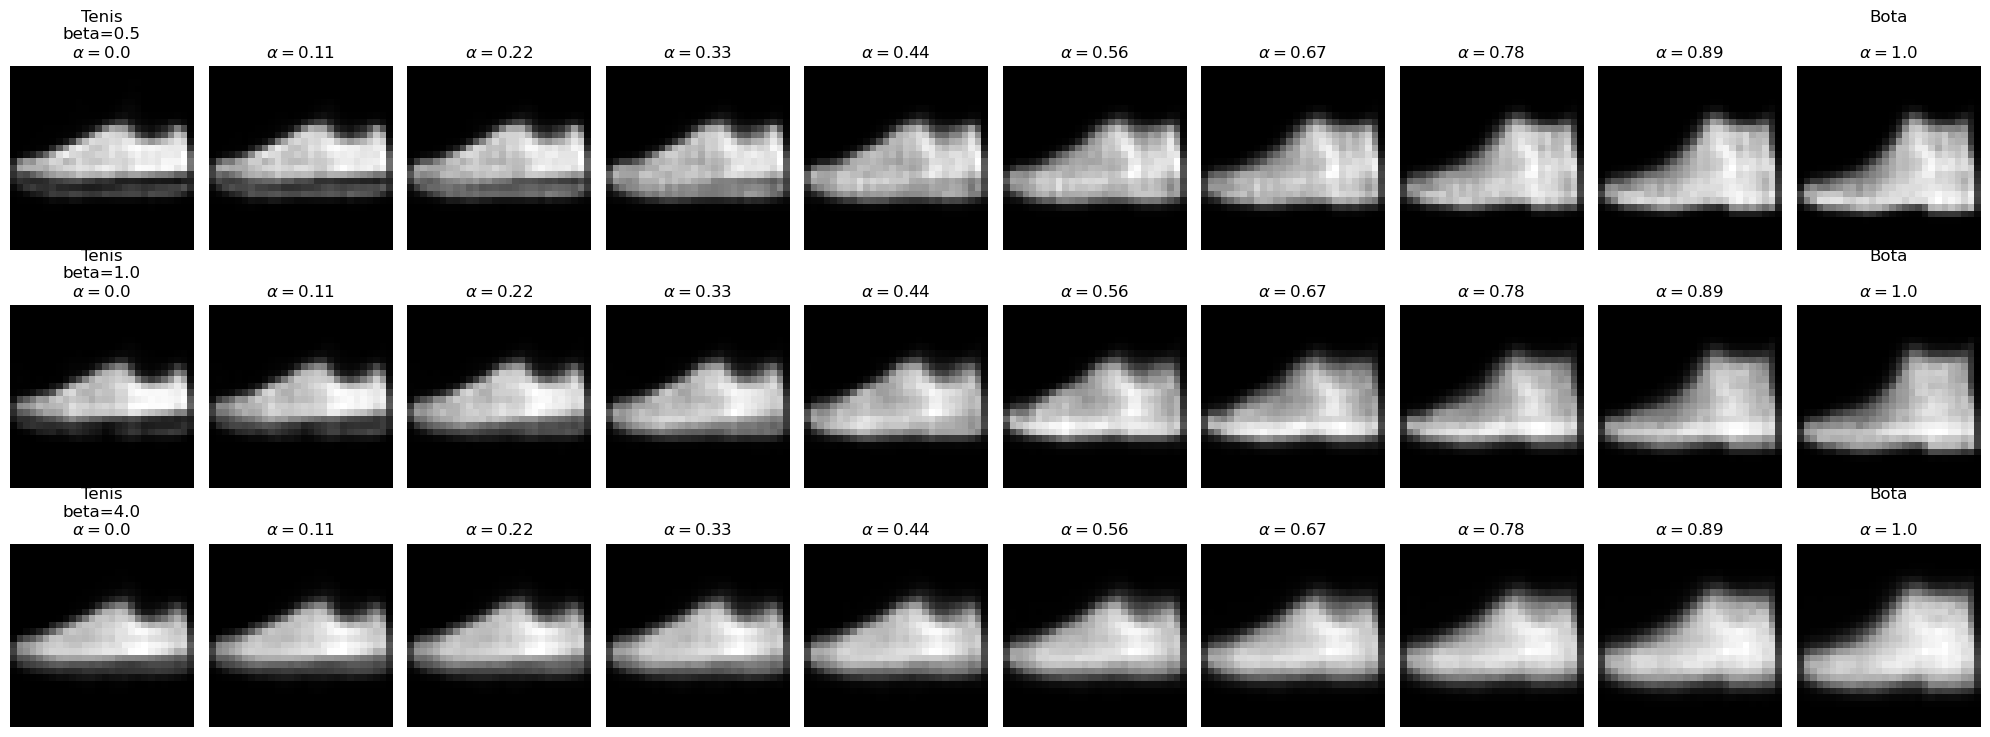

In [14]:
# Tenis -> Bota
plot_transition(7, 9)

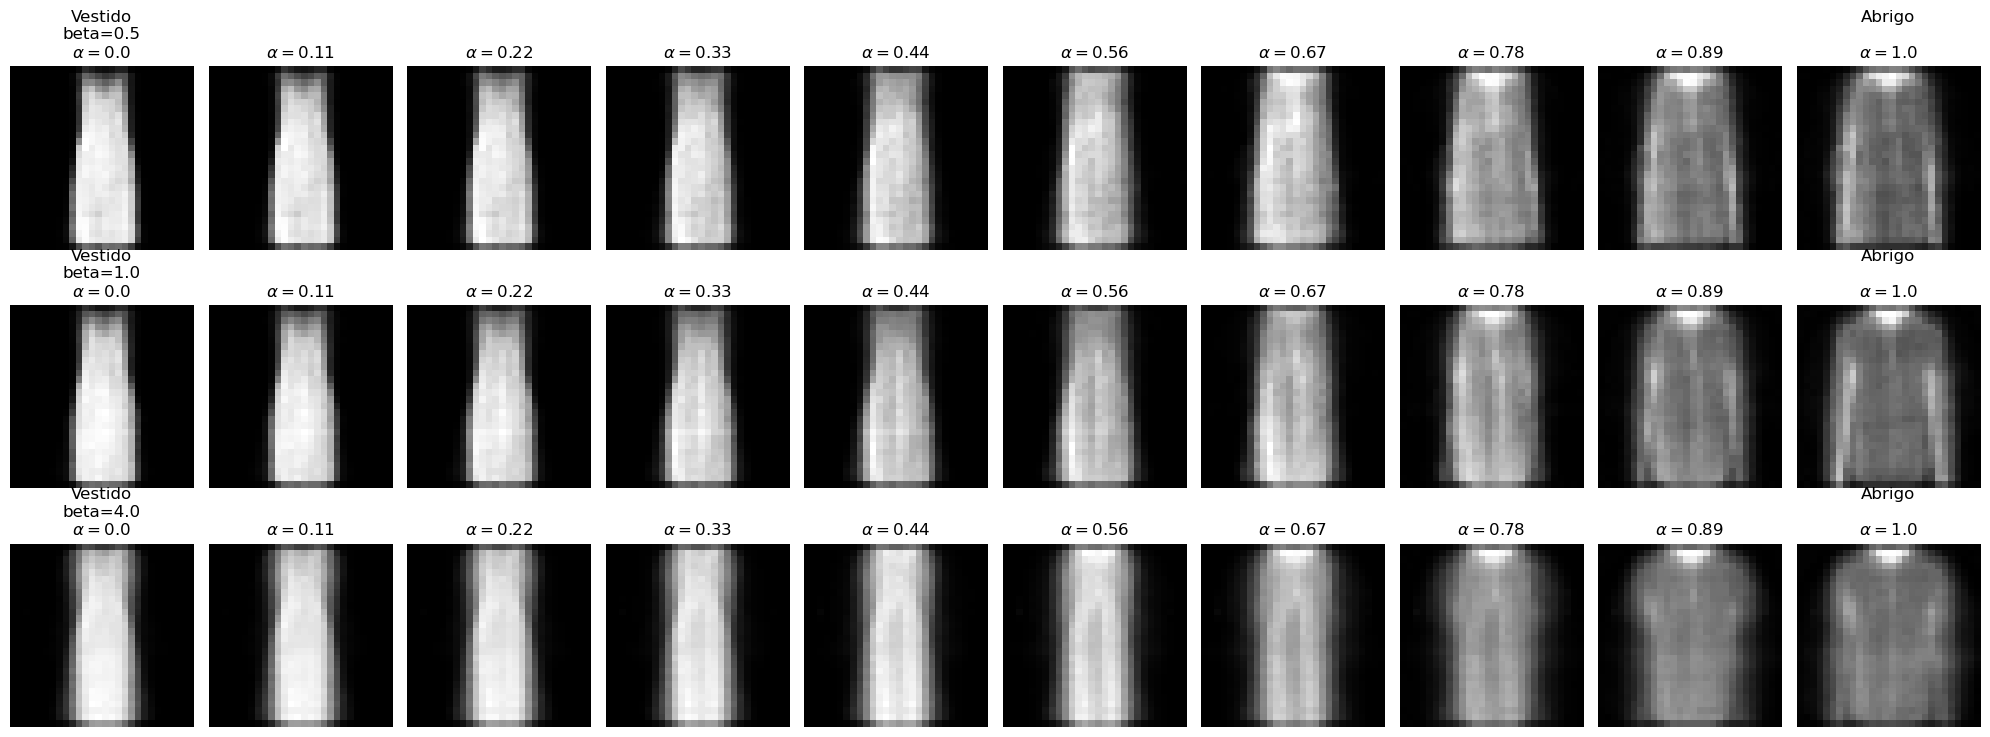

In [15]:
# Vestido -> Abrigo
plot_transition(3, 4)

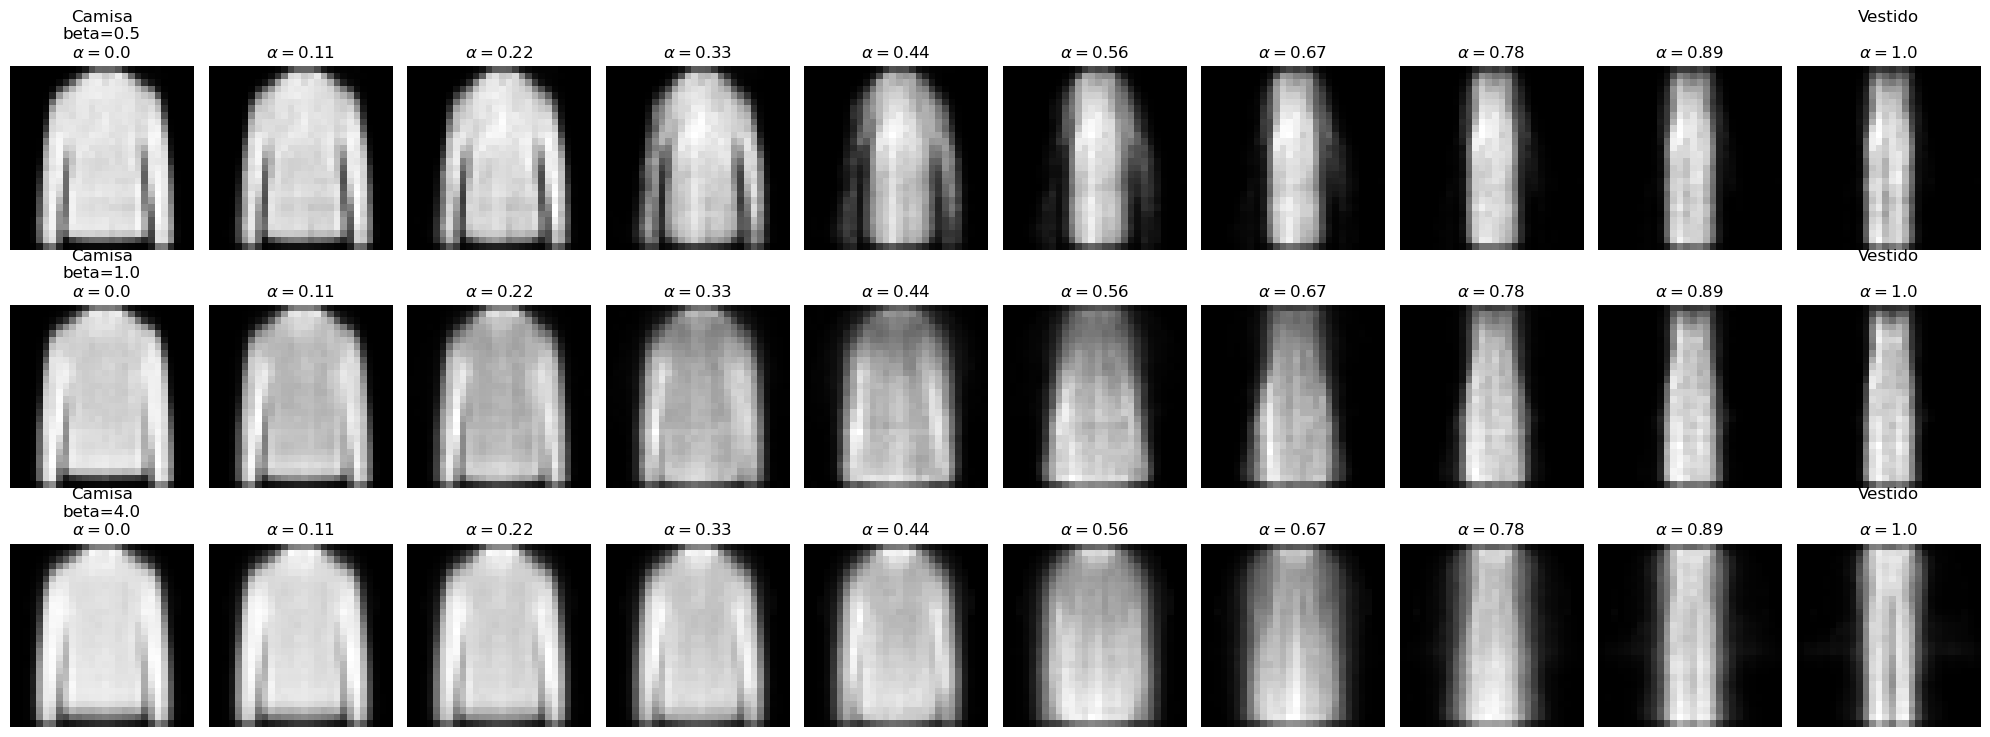

In [16]:
# Clases: 0 Playera, 1 Pantalón, 2 Suéter, 3 Vestido, 4 Abrigo,
# 5 Sandalia, 6 Camisa, 7 Tenis, 8 Bolsa, 9 Bota
plot_transition(6, 3, k=2)

## 10.  Experimentos

Calculando la diferencia entre las representaciones medias de dos clases distintas en el espacio latente. Aplicamos esta dirección a una prenda específica (como un vestido sin mangas) para transferirle ese atributo en particular, intentando agregarle mangas sin alterar su forma o estructura general.

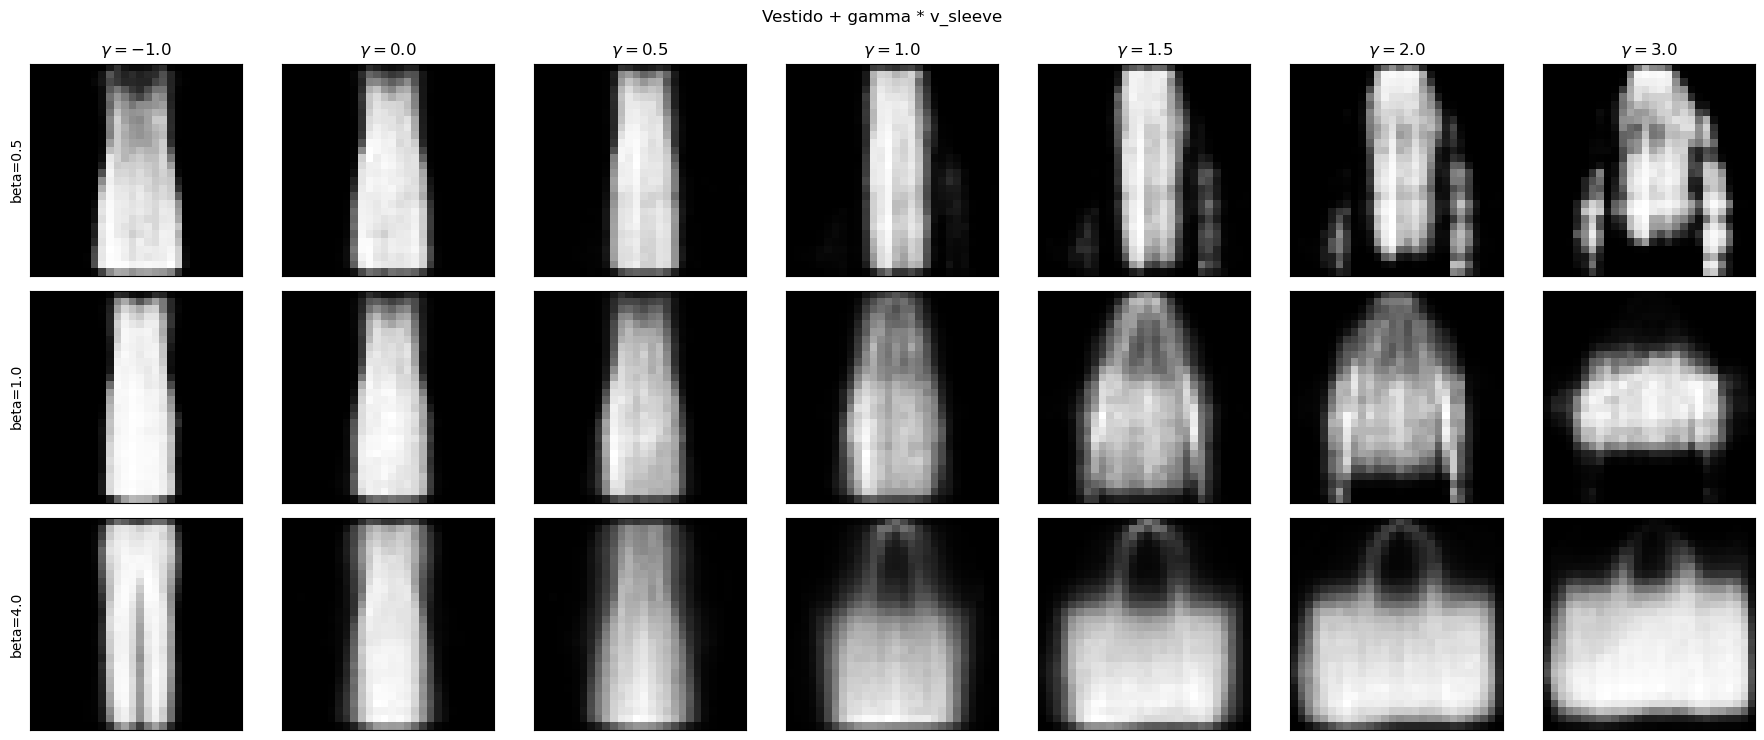

In [17]:
gammas = [-1.0, 0.0, 0.5, 1.0, 1.5, 2.0, 3.0]
dress_idx = np.where(y_test == 3)[0][0]      # un vestido del conjunto de prueba

plt.figure(figsize=(18, 2.5 * len(betas)))
for r, beta in enumerate(betas):
    # Medias latentes de todo el conjunto de prueba
    z_all, _, _ = vaes[beta].encoder.predict(x_test, batch_size=1000, verbose=0)

    # v_sleeve = media(Suéter) - media(Playera)
    v_sleeve = z_all[y_test == 2].mean(axis=0) - z_all[y_test == 0].mean(axis=0)

    # z_vestido + gamma * v_sleeve para cada gamma
    z_dress = z_all[dress_idx]
    z_new = np.vstack([z_dress + g * v_sleeve for g in gammas])
    new_images = vaes[beta].decoder.predict(z_new, verbose=0)

    for j in range(len(gammas)):
        plt.subplot(len(betas), len(gammas), r * len(gammas) + j + 1)
        plt.imshow(new_images[j].reshape(28, 28), cmap="gray")
        if r == 0:
            plt.title(f"$\\gamma = {gammas[j]}$")
        if j == 0:
            plt.ylabel(f"beta={beta}")
        plt.xticks([])
        plt.yticks([])

plt.suptitle("Vestido + gamma * v_sleeve")
plt.tight_layout()
plt.show()

## 11. Análisis de Fallas

Para identificar las regiones donde las diferentes categorías se mezclan dentro del espacio latente, aplicamos dos estrategias de evaluación complementarias:

1. Visualización mediante Reducción de Dimensionalidad: Proyectamos las medias latentes a un espacio bidimensional utilizando el Análisis de Componentes Principales (PCA), aplicando un código de colores por clase para observar gráficamente su distribución y proximidad.
2. Evaluamos cada imagen del conjunto de prueba asignándole la etiqueta correspondiente a la media de clase más cercana en el espacio latente. Los errores detectados mediante este enfoque revelan directamente qué clases presentan un mayor nivel de traslape y, por ende, mayor confusión para el modelo.

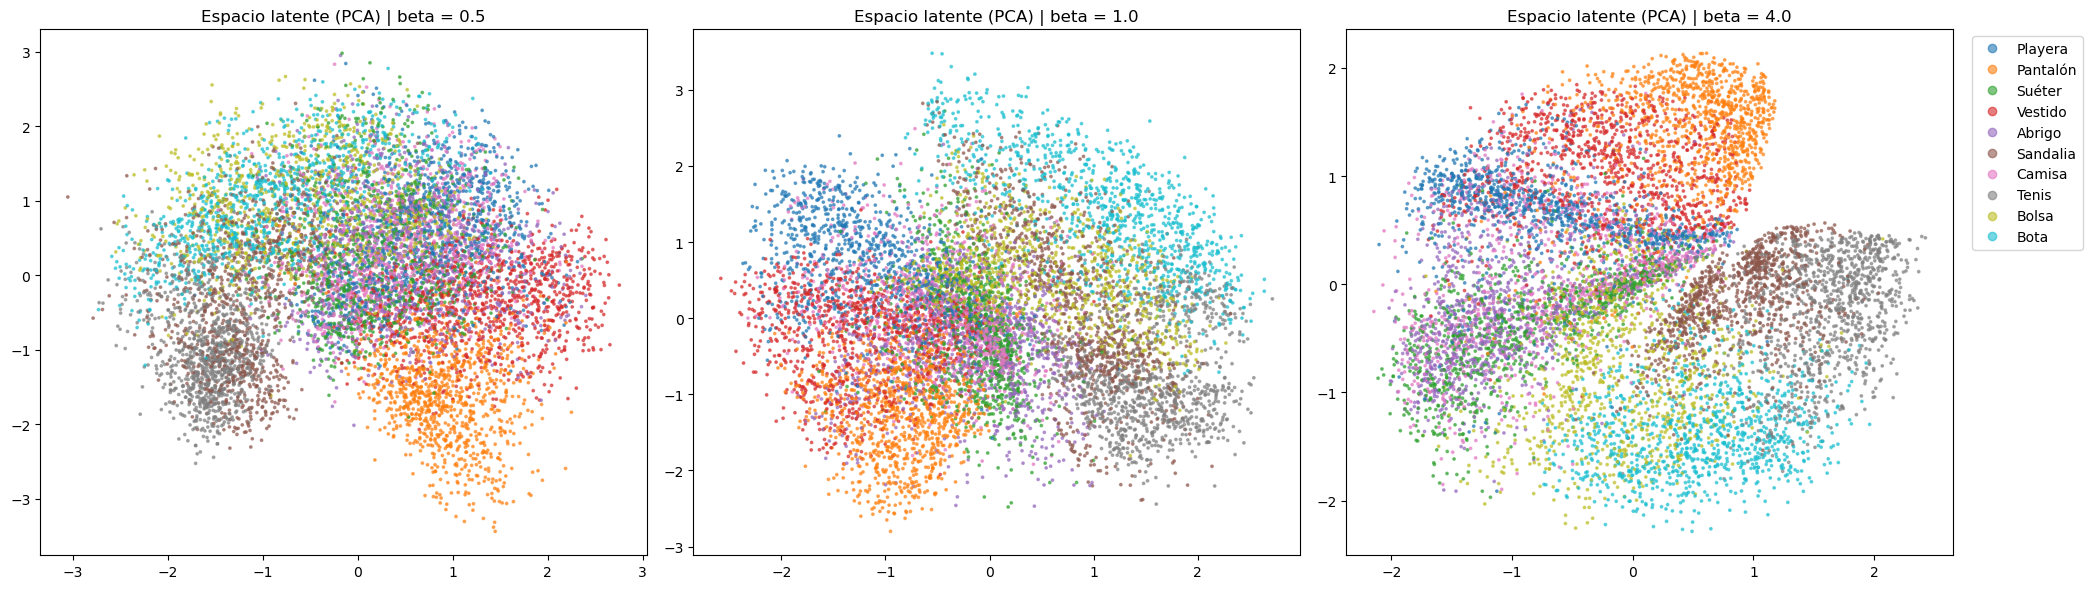

In [18]:
from sklearn.decomposition import PCA

# 1. Proyección PCA del espacio latente
plt.figure(figsize=(7 * len(betas), 6))
z_test = {}
for k, beta in enumerate(betas):
    z_test[beta], _, _ = vaes[beta].encoder.predict(x_test, batch_size=1000, verbose=0)
    p = PCA(n_components=2).fit_transform(z_test[beta])

    plt.subplot(1, len(betas), k + 1)
    sc = plt.scatter(p[:, 0], p[:, 1], c=y_test, cmap="tab10", s=3, alpha=0.6)
    plt.title(f"Espacio latente (PCA) | beta = {beta}")

plt.legend(handles=sc.legend_elements()[0], labels=class_names,
           bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [19]:
# 2. Clasificación por media de clase más cercana
for beta in betas:
    z_all = z_test[beta]

    # Media latente de cada clase (10 x latent_dim)
    class_means = np.array([z_all[y_test == c].mean(axis=0) for c in range(10)])

    # Distancia de cada imagen a cada media y clase más cercana
    dist = np.linalg.norm(z_all[:, None, :] - class_means[None, :, :], axis=2)
    pred = dist.argmin(axis=1)

    print(f"\nbeta = {beta} | exactitud = {(pred == y_test).mean():.3f}")
    # Qué clases se confunden más
    for c in range(10):
        mask = y_test == c
        confused = np.bincount(pred[mask], minlength=10)
        confused[c] = 0
        worst = confused.argmax()
        print(f"  {class_names[c]:<9} se confunde más con {class_names[worst]:<9} ({confused[worst] / mask.sum():.0%})")


beta = 0.5 | exactitud = 0.696
  Playera   se confunde más con Vestido   (10%)
  Pantalón  se confunde más con Vestido   (7%)
  Suéter    se confunde más con Abrigo    (24%)
  Vestido   se confunde más con Abrigo    (10%)
  Abrigo    se confunde más con Suéter    (18%)
  Sandalia  se confunde más con Tenis     (19%)
  Camisa    se confunde más con Playera   (21%)
  Tenis     se confunde más con Sandalia  (10%)
  Bolsa     se confunde más con Tenis     (6%)
  Bota      se confunde más con Tenis     (8%)

beta = 1.0 | exactitud = 0.654
  Playera   se confunde más con Vestido   (12%)
  Pantalón  se confunde más con Vestido   (9%)
  Suéter    se confunde más con Abrigo    (25%)
  Vestido   se confunde más con Camisa    (10%)
  Abrigo    se confunde más con Suéter    (18%)
  Sandalia  se confunde más con Tenis     (22%)
  Camisa    se confunde más con Playera   (21%)
  Tenis     se confunde más con Sandalia  (9%)
  Bolsa     se confunde más con Suéter    (13%)
  Bota      se confunde más c

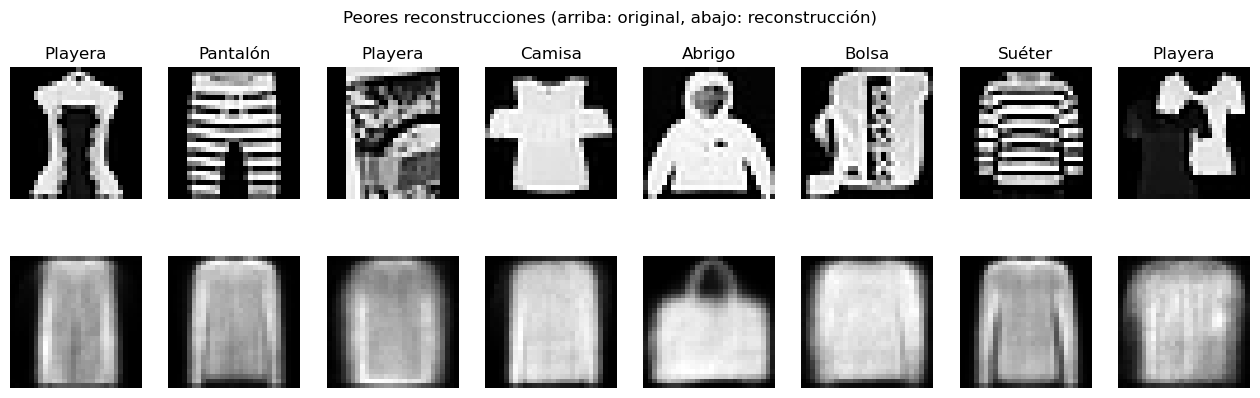

In [20]:
# 3. Peores reconstrucciones (posibles artefactos) con beta = 1.0
z_all = z_test[1.0]
recon = vaes[1.0].decoder.predict(z_all, batch_size=1000, verbose=0)

# Error cuadrático de cada imagen
err = ((x_test - recon) ** 2).sum(axis=1)
worst = np.argsort(err)[-8:]

plt.figure(figsize=(16, 4.5))
for j, idx in enumerate(worst):
    plt.subplot(2, 8, j + 1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap="gray")
    plt.title(class_names[y_test[idx]])
    plt.axis("off")
    plt.subplot(2, 8, 8 + j + 1)
    plt.imshow(recon[idx].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.suptitle("Peores reconstrucciones (arriba: original, abajo: reconstrucción)")
plt.show()

## 11.  Modificación de Arquitectura: Capas Ocultas y Espacio Latente

Para analizar cómo la profundidad de la red y la capacidad del cuello de botella afectan el rendimiento del modelo, se evalúan diferentes configuraciones. En esta sección, fijamos el hiperparámetro $\beta = 1.0$ y reducimos el número de épocas de entrenamiento, variando  la cantidad de capas ocultas y la dimensión del espacio latente (`latent_dim`).

In [21]:
exp_epochs = 8
configs = [
    # (latent_dim, hidden_layers)
    (2,  [256, 128]),
    (8,  [256, 128]),
    (32, [256, 128]),
    (16, [128]),                # menos capas
    (16, [512, 256, 128]),      # más capas
]

# Guardamos los valores originales para restaurarlos al final
old_latent, old_hidden = latent_dim, hidden_layers

exp_models = []
for ld, hl in configs:
    latent_dim, hidden_layers = ld, hl
    keras.utils.set_random_seed(42)
    m = BetaVAE(build_encoder(), build_decoder(), beta=1.0)
    m.compile(optimizer="adam")
    h = m.fit(x_train, x_train, epochs=exp_epochs, batch_size=batch_size, verbose=0).history
    exp_models.append(m)
    print(f"latent_dim={ld:<3} capas={str(hl):<16} recon={h['reconstruction_loss'][-1]:.2f} | KL={h['kl_loss'][-1]:.2f}")

latent_dim, hidden_layers = old_latent, old_hidden

latent_dim=2   capas=[256, 128]       recon=24.85 | KL=4.63
latent_dim=8   capas=[256, 128]       recon=18.12 | KL=7.23
latent_dim=32  capas=[256, 128]       recon=18.52 | KL=6.99
latent_dim=16  capas=[128]            recon=19.61 | KL=7.91
latent_dim=16  capas=[512, 256, 128]  recon=18.15 | KL=6.60


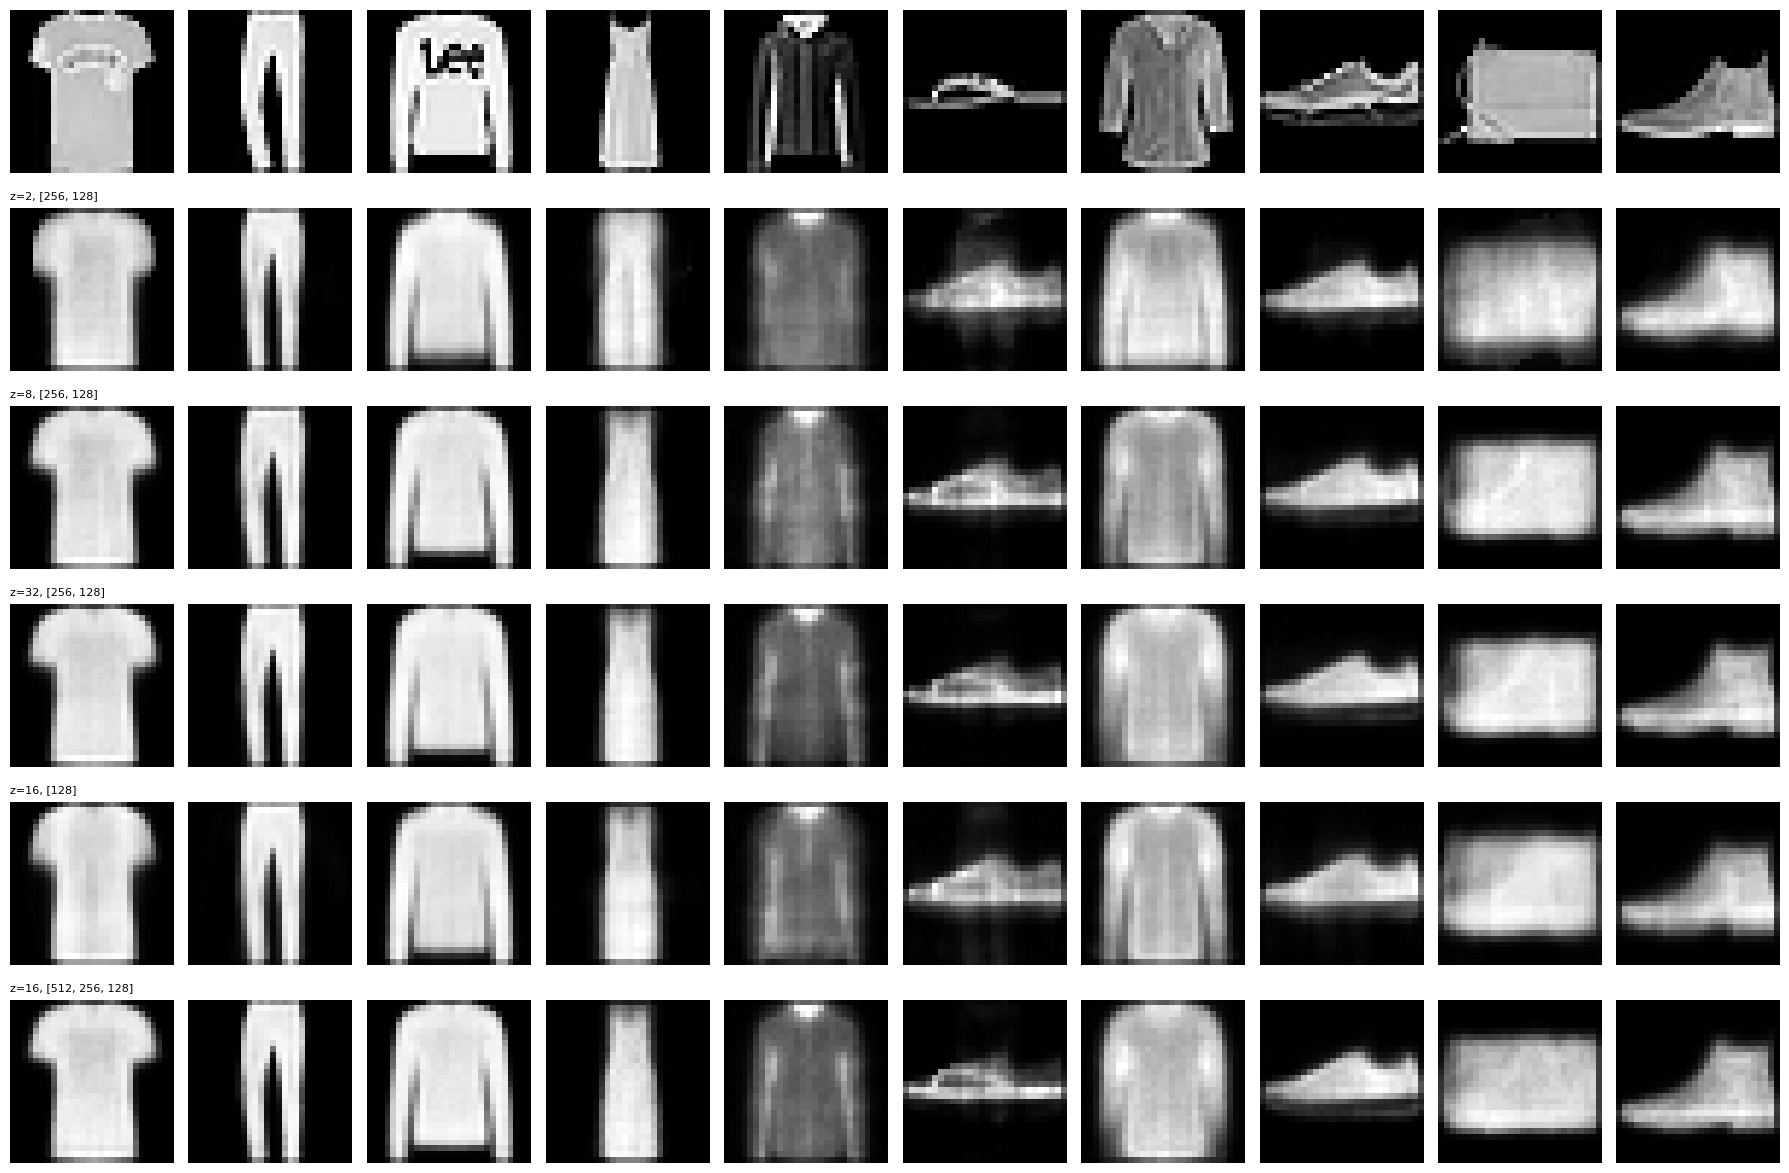

In [22]:
# Comparar las reconstrucciones de cada configuración
plt.figure(figsize=(18, 2 * (len(exp_models) + 1)))
for i in range(10):
    plt.subplot(len(exp_models) + 1, 10, i + 1)
    plt.imshow(originals[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

for r, m in enumerate(exp_models):
    z_mean, _, _ = m.encoder.predict(originals, verbose=0)
    recon = m.decoder.predict(z_mean, verbose=0)
    for i in range(10):
        plt.subplot(len(exp_models) + 1, 10, (r + 1) * 10 + i + 1)
        plt.imshow(recon[i].reshape(28, 28), cmap="gray")
        if i == 0:
            plt.title(f"z={configs[r][0]}, {configs[r][1]}", loc="left", fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.show()